# Books Dataset: EDA & Data Visualization
**CodeAlpha Data Analytics Internship | Tasks 2 & 3**

Data source: `data/books.csv`, scraped from books.toscrape.com in Task 1.

## Questions I want to answer
1. What does the dataset look like (size, columns, data types)? Are there data quality issues?
2. How are book prices distributed? Are there outliers?
3. How are ratings distributed?
4. Do higher-rated books cost more?
5. Which categories have the most books, and which are the most expensive?

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

os.makedirs("../images", exist_ok=True)  # charts will be saved here

Matplotlib is building the font cache; this may take a moment.


## 1. Load and inspect the data

In [2]:
df = pd.read_csv("../data/books.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (1000, 6)


,title,category,price_gbp,rating,availability,url
0,It's Only the Himalayas,Travel,45.17,2,In stock,https://books.toscrape.com/catalogue/its-only-...
1,Full Moon over Noah’s Ark: An Odyssey to Mount...,Travel,49.43,4,In stock,https://books.toscrape.com/catalogue/full-moon...
2,See America: A Celebration of Our National Par...,Travel,48.87,3,In stock,https://books.toscrape.com/catalogue/see-ameri...
3,Vagabonding: An Uncommon Guide to the Art of L...,Travel,36.94,2,In stock,https://books.toscrape.com/catalogue/vagabondi...
4,Under the Tuscan Sun,Travel,37.33,3,In stock,https://books.toscrape.com/catalogue/under-the...


In [ ]:
df.info()

In [4]:
df.describe(include='all')

,title,category,price_gbp,rating,availability,url
count,1000,1000,1000.00000,1000.000000,1000,1000
unique,999,50,NaN,NaN,1,1000
top,The Star-Touched Queen,Default,NaN,NaN,In stock,https://books.toscrape.com/catalogue/its-only-...
freq,2,152,NaN,NaN,1000,1
mean,NaN,NaN,35.07035,2.923000,NaN,NaN
std,NaN,NaN,14.44669,1.434967,NaN,NaN
min,NaN,NaN,10.00000,1.000000,NaN,NaN
25%,NaN,NaN,22.10750,2.000000,NaN,NaN
50%,NaN,NaN,35.98000,3.000000,NaN,NaN
75%,NaN,NaN,47.45750,4.000000,NaN,NaN


## 2. Data quality checks

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate titles:", df['title'].duplicated().sum())
print("\nAvailability values:")
print(df['availability'].value_counts())

Missing values per column:
title           0
category        0
price_gbp       0
rating          0
availability    0
url             0
dtype: int64

Duplicate rows: 0
Duplicate titles: 1

Availability values:
availability
In stock    1000
Name: count, dtype: int64


**Notes:** Check the output above. If duplicate titles appear, they may be different books with the same name. If every book shows the same availability, that column carries no useful information for analysis.

## 3. Price analysis

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price_gbp, dtype: float64


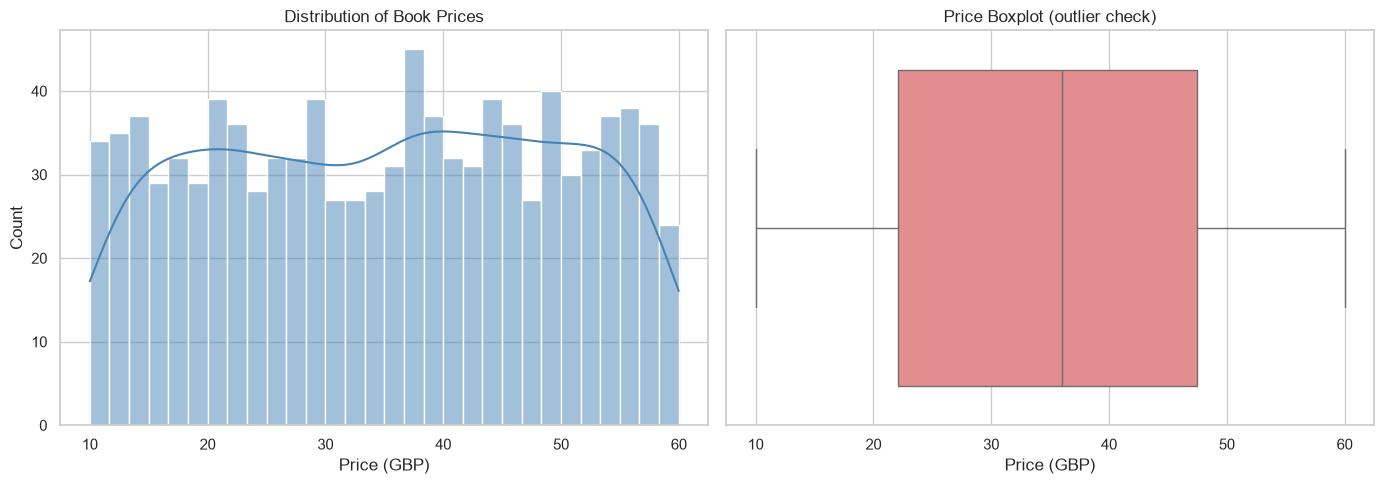

In [6]:
print(df['price_gbp'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price_gbp'], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Book Prices")
axes[0].set_xlabel("Price (GBP)")

sns.boxplot(x=df['price_gbp'], ax=axes[1], color="lightcoral")
axes[1].set_title("Price Boxplot (outlier check)")
axes[1].set_xlabel("Price (GBP)")

plt.tight_layout()
plt.savefig("../images/price_distribution.png", dpi=150)
plt.show()

In [7]:
# Outlier detection using the IQR rule
q1, q3 = df['price_gbp'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df['price_gbp'] < low) | (df['price_gbp'] > high)]
print(f"Price outlier range: below {low:.2f} or above {high:.2f}")
print("Number of outliers:", len(outliers))
outliers.head()

Price outlier range: below -15.92 or above 85.48
Number of outliers: 0


,title,category,price_gbp,rating,availability,url


## 4. Rating analysis

rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_11104\2097905152.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="viridis")


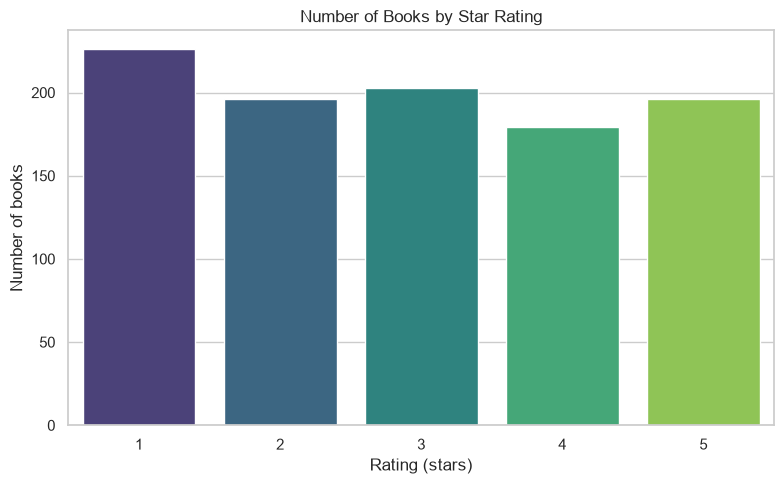

In [8]:
rating_counts = df['rating'].value_counts().sort_index()
print(rating_counts)

plt.figure(figsize=(8, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="viridis")
plt.title("Number of Books by Star Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of books")
plt.tight_layout()
plt.savefig("../images/rating_distribution.png", dpi=150)
plt.show()

## 5. Do higher-rated books cost more?

        count   mean  median
rating                      
1         226  34.56   34.77
2         196  34.81   36.22
3         203  34.69   33.78
4         179  36.09   37.80
5         196  35.37   36.90


C:\Users\Admin\AppData\Local\Temp\ipykernel_11104\617510233.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='rating', y='price_gbp', palette="Set2")


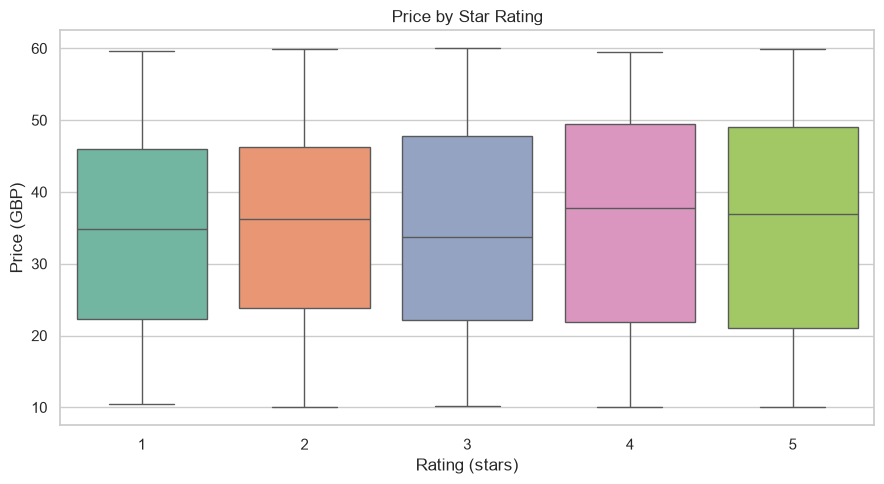

Spearman correlation between price and rating: 0.029


In [9]:
print(df.groupby('rating')['price_gbp'].agg(['count', 'mean', 'median']).round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='rating', y='price_gbp', palette="Set2")
plt.title("Price by Star Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Price (GBP)")
plt.tight_layout()
plt.savefig("../images/price_by_rating.png", dpi=150)
plt.show()

# Spearman correlation (works for ordinal ratings)
corr = df['price_gbp'].corr(df['rating'], method='spearman')
print(f"Spearman correlation between price and rating: {corr:.3f}")

**Interpretation guide:** A correlation close to 0 means price and rating are basically unrelated. Values near +1 or -1 would mean a strong relationship.

## 6. Category analysis

category
Default           152
Nonfiction        110
Sequential Art     75
Add a comment      67
Fiction            65
Young Adult        54
Fantasy            48
Romance            35
Mystery            32
Food and Drink     30
Name: count, dtype: int64


C:\Users\Admin\AppData\Local\Temp\ipykernel_11104\740058266.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette="mako")


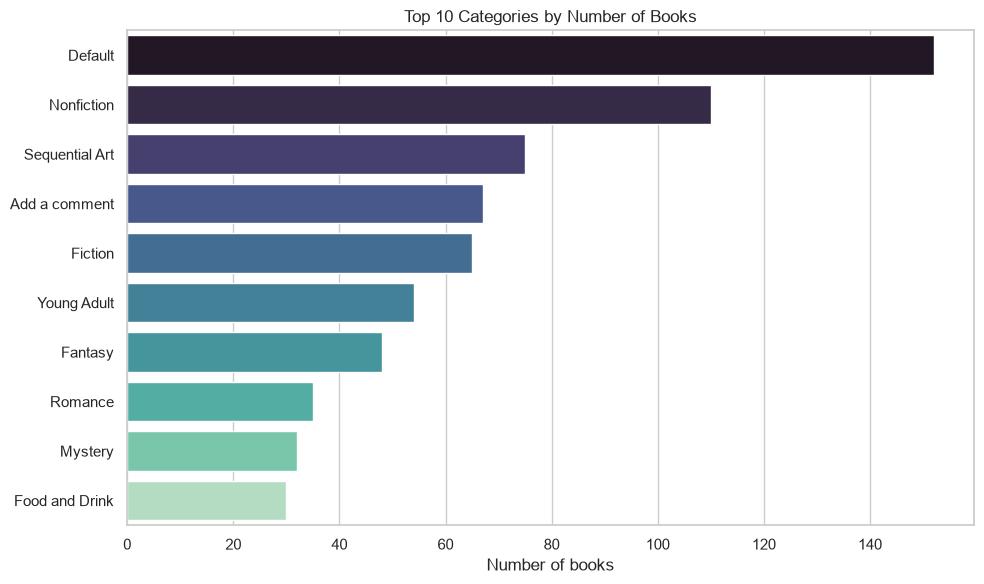

In [10]:
top_categories = df['category'].value_counts().head(10)
print(top_categories)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.values, y=top_categories.index, palette="mako")
plt.title("Top 10 Categories by Number of Books")
plt.xlabel("Number of books")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/top_categories.png", dpi=150)
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_11104\2079552542.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top['mean'], y=top.index, palette="rocket")


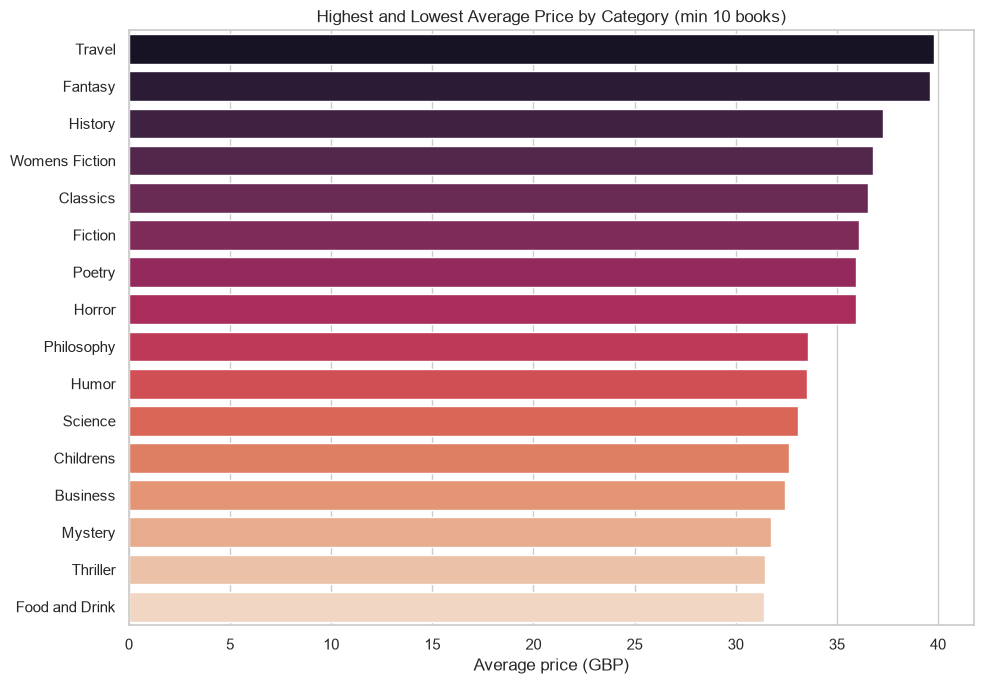

In [11]:
# Average price per category (only categories with at least 10 books)
cat_stats = df.groupby('category')['price_gbp'].agg(['count', 'mean']).round(2)
cat_stats = cat_stats[cat_stats['count'] >= 10].sort_values('mean', ascending=False)

top = pd.concat([cat_stats.head(8), cat_stats.tail(8)])

plt.figure(figsize=(10, 7))
sns.barplot(x=top['mean'], y=top.index, palette="rocket")
plt.title("Highest and Lowest Average Price by Category (min 10 books)")
plt.xlabel("Average price (GBP)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../images/avg_price_by_category.png", dpi=150)
plt.show()

In [12]:
# Average rating per category
rating_stats = df.groupby('category')['rating'].agg(['count', 'mean']).round(2)
rating_stats = rating_stats[rating_stats['count'] >= 10].sort_values('mean', ascending=False)
rating_stats.head(10)

,count,mean
category,,
Poetry,19,3.53
Humor,10,3.40
Young Adult,54,3.30
Historical Fiction,26,3.23
Fiction,65,3.18
Music,13,3.15
Womens Fiction,17,3.12
Fantasy,48,3.08
Sequential Art,75,2.97


## 7. Key insights

1. **Prices:** Prices range from £10.00 to £59.99, with a mean of £35.07 and a median of £35.98. The IQR rule found no outliers, so the prices are spread fairly evenly.
2. **Ratings:** Ratings are well balanced. 1-star is the most common (226 books) and 4-star the least (179). The average rating is 2.92.
3. **Price vs rating:** There is no meaningful relationship. Average price stays between £34.56 and £36.09 for every rating, and the Spearman correlation is 0.029 (close to 0).
4. **Categories:** The largest categories are Default (152), Nonfiction (110) and Sequential Art (75). Among categories with at least 10 books, Poetry (3.53), Humor (3.40) and Young Adult (3.30) have the highest average ratings.
5. **Data issues:** The availability column is "In stock" for all 1,000 books, so it has no analytical value. One title appears twice (different books with the same name). "Default" and "Add a comment" look like placeholder categories on the source site rather than real genres.

## 8. Conclusion

This analysis of 1,000 scraped books showed a clean dataset with evenly spread prices and ratings, and no link between how much a book costs and how it is rated. This is likely because books.toscrape.com is a practice website with synthetic data. A next step would be to run sentiment analysis on a real review dataset to study how customer opinion relates to ratings.